# 02 · Model and sampler

Which Bayesian model do we fit to the returns, and can we trust our own Metropolis–Hastings sampler to compute its posterior?

| Reads | Produces | Running time |
|---|---|---|
| `data/returns.csv`<br>`tools.py` (model, sampler, diagnostics) | `../report/tables/prior_predictive.tex` (report, Section 3 and appendix)<br>`../report/tables/known_answers.tex`, `../report/figures/known_answers.pdf` (report, Section 4 and appendix) | about 10 seconds |

01 Data → **02 Model and sampler** → 03 Validation → 04 Posterior → 05 Risk → 06 Checks

In [1]:
# Setup: libraries, our shared functions and the constants of this notebook
import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from tools import (BURN_IN, COLOR_OTHER, PRIOR, convergence_checks, log_likelihood, log_prior,
                   metropolis, run_chains, save_figure, save_table, set_style, summarize, to_phi,
                   to_theta, var_t)

SEED = 2026
rng = np.random.default_rng(SEED)
N_PRIOR_DRAWS = 100_000  # draws for the prior predictive check

# The daily log-returns of notebook 01, in decimals
y = pd.read_csv("data/returns.csv", index_col="date", parse_dates=True)["y"].to_numpy()
n = len(y)
set_style()

## 1. The model

We need the distribution of the one-day loss $L = -y$, and above all its far tail. Notebook 01 showed that a Gaussian is far too light there. We model the daily log-returns as independent draws from a **Student-t distribution** with location $\mu$, scale $\sigma$ and $\nu$ degrees of freedom, $\theta = (\mu, \sigma, \nu)$:

$$y_t \mid \theta \;\overset{\text{iid}}{\sim}\; t_\nu(\mu, \sigma), \qquad
p(y_t \mid \theta) = \frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left[1 + \frac{1}{\nu}\left(\frac{y_t-\mu}{\sigma}\right)^{2}\right]^{-\frac{\nu+1}{2}}, \qquad t = 1, \dots, n.$$

| Symbol | Name | Meaning |
|---|---|---|
| $\mu \in \mathbb{R}$ | location | the centre of the daily returns |
| $\sigma > 0$ | scale | the spread; **not** the standard deviation, which is $\sigma\sqrt{\nu/(\nu-2)}$ |
| $\nu > 2$ | degrees of freedom | the **tail heaviness**: the density decays like $\lvert y\rvert^{-(\nu+1)}$, so a small $\nu$ means heavy tails, and $\nu \to \infty$ gives back the Gaussian |

As a **Bayesian network**, the three unknowns point to every observed day (a plate repeated $n$ times):

```
      μ          σ          ν            unknown parameters, each with a prior
       \         |         /
        v        v        v
   +-----------------------------+
   |             y_t             |       observed daily log-return
   |                 t = 1, …, n |
   +-----------------------------+
```

**Assumptions.**
1. Given $\theta$, the days are **independent**. Notebook 01 showed volatility clustering, so this is our main limitation: the model describes a typical day of the window, not tomorrow given today.
2. The **same distribution** holds over the whole window.
3. The tails are **symmetric**: large losses and large gains are equally likely.
4. $\nu > 2$, so that the variance is finite.

The log-likelihood is $\ell(\theta) = \sum_{t=1}^n \log p(y_t \mid \theta)$, and the posterior follows from Bayes' theorem up to a constant, $\pi(\theta \mid y) \propto \tilde\pi(\theta \mid y) = p(y \mid \theta)\,\pi(\theta)$.

> **[COURSE]** Unnormalized posterior: Ch. 1, Sec. 1.2.2, Definition 1.3 (p. 15); log scale against underflow: Sec. 1.3.1, Remark 1.3 (p. 20).
> The evidence $p(y)$ is never needed, and a product of 5,031 densities would round to 0, so we always sum log densities.

In [2]:
# Check our hand-written log-likelihood (tools.py) against SciPy's Student-t density
rows = []
for theta in [(0.0005, 0.007, 3.0), (0.0, 0.010, 10.0), (0.001, 0.005, 2.5)]:
    ours = log_likelihood(theta, y)
    scipy_value = stats.t.logpdf(y, df=theta[2], loc=theta[0], scale=theta[1]).sum()
    rows.append([str(theta), ours, scipy_value, ours - scipy_value])
pd.DataFrame(rows, columns=["theta = (mu, sigma, nu)", "ours", "SciPy", "difference"])

,"theta = (mu, sigma, nu)",ours,SciPy,difference
0,"(0.0005, 0.007, 3.0)",15752.768926,15752.768926,-1.818989e-12
1,"(0.0, 0.01, 10.0)",15474.538466,15474.538466,-1.818989e-12
2,"(0.001, 0.005, 2.5)",15544.986950,15544.986950,0.000000e+00


## 2. The priors

We use independent, **weakly informative** priors, in the units of daily log-returns (0.01 = 1%):

| Parameter | Prior | Why |
|---|---|---|
| $\mu$ | $\mathcal N(0,\ 0.001^2)$ | rules out absurd daily drifts, while staying far wider than what 5,031 days pin down |
| $\sigma$ | HalfNormal$(0.02)$, a $\mathcal N(0, 0.02^2)$ folded onto $\sigma > 0$ | covers calm and crisis markets alike |
| $\nu - 2$ | Exponential with **rate** $0.1$ (mean 10) | lets the data choose between very heavy and almost Gaussian tails |

A warning for the code: NumPy and SciPy parametrize the exponential distribution by its **scale** $1/\lambda$, not its rate $\lambda$, so the prior is `rng.exponential(1 / 0.1)`. Mixing the two up is a classic silent bug. The cell below translates each prior into plain statements.

In [3]:
# What each prior says, in numbers (exact, from the prior distributions)
prior_mu = stats.norm(0, PRIOR["mu_sd"])
prior_sigma = stats.halfnorm(scale=PRIOR["sigma_scale"])
prior_nu_minus_min = stats.expon(scale=1 / PRIOR["nu_rate"])  # SciPy takes the scale = 1 / rate

print(f"mu:    95% of the prior mass within ±{100 * prior_mu.ppf(0.975):.2f}% a day")
print(f"sigma: 95% of the prior mass below a daily scale of {100 * prior_sigma.ppf(0.95):.1f}%")
print(f"nu:    prior median {PRIOR['nu_min'] + prior_nu_minus_min.median():.1f}, "
      f"Pr(nu < 5) = {prior_nu_minus_min.cdf(5 - PRIOR['nu_min']):.2f}, "
      f"Pr(nu > 30) = {prior_nu_minus_min.sf(30 - PRIOR['nu_min']):.2f}")

mu:    95% of the prior mass within ±0.20% a day
sigma: 95% of the prior mass below a daily scale of 3.9%
nu:    prior median 8.9, Pr(nu < 5) = 0.26, Pr(nu > 30) = 0.06


### 2.1 Prior predictive check

Do these priors describe plausible markets? We draw $\theta$ from the prior and compute two quantities that matter for our question: the **implied daily standard deviation** $\sigma\sqrt{\nu/(\nu-2)}$ and the **99% VaR** $-\mu + \sigma\, t_\nu^{-1}(0.99)$. Each prior quantile is a Monte Carlo estimate from the draws. We compare them with the values of our data: the sample standard deviation, and the historical 99% VaR (minus the 1% quantile of the returns).

> **[COURSE]** Monte Carlo estimator: Ch. 1, Sec. 1.4.2, Definition 1.7 (p. 23).
> A quantity of the prior (here, its quantiles) is estimated from independent draws of the prior.

In [4]:
# Draw theta from the prior: mu ~ Normal, sigma ~ HalfNormal, nu = nu_min + Exponential(scale = 1 / rate)
mu_draws = rng.normal(0, PRIOR["mu_sd"], N_PRIOR_DRAWS)
sigma_draws = np.abs(rng.normal(0, PRIOR["sigma_scale"], N_PRIOR_DRAWS))
nu_draws = PRIOR["nu_min"] + rng.exponential(1 / PRIOR["nu_rate"], N_PRIOR_DRAWS)
theta_prior = np.column_stack([mu_draws, sigma_draws, nu_draws])

# Implied daily sd and 99% VaR of each draw, in %, against the values of our data
sd_prior = 100 * sigma_draws * np.sqrt(nu_draws / (nu_draws - 2))
var99_prior = 100 * var_t(theta_prior, 0.99)
sd_data = 100 * y.std(ddof=1)
var99_data = -100 * np.quantile(y, 0.01)

prior_predictive = pd.DataFrame(
    [np.append(np.quantile(sd_prior, [0.025, 0.5, 0.975]), sd_data),
     np.append(np.quantile(var99_prior, [0.025, 0.5, 0.975]), var99_data)],
    index=["Daily sd (%)", "99% VaR (%)"],
    columns=["Prior 2.5%", "Prior median", "Prior 97.5%", "Our data"]).round(3)
prior_predictive.index.name = "Quantity"
save_table(prior_predictive, "prior_predictive.tex", fmt="{:.3f}")
prior_predictive

,Prior 2.5%,Prior median,Prior 97.5%,Our data
Quantity,,,,
Daily sd (%),0.075,1.654,6.783,1.246
99% VaR (%),0.190,4.071,15.757,3.598


**What we see.** The priors allow markets from very calm (a daily VaR well below 1%) to extreme crises (above 10%), and our data sit comfortably inside, close to the prior median. The priors exclude only absurd markets; the 5,031 days, not the priors, will decide where $\theta$ lies. Notebook 06 checks this by changing the priors.

## 3. Sampling on an unconstrained scale

A random walk proposes moves anywhere on the real line, but $\sigma > 0$ and $\nu > 2$. We therefore sample

$$\phi = (\mu,\ \eta,\ \lambda) = \big(\mu,\ \log\sigma,\ \log(\nu - 2)\big) \in \mathbb{R}^3,$$

where every value is valid. The density of $\phi$ is the density of $\theta$ times the Jacobian $|d\sigma/d\eta| \cdot |d\nu/d\lambda| = \sigma\,(\nu-2)$, so on the log scale

$$\log\tilde\pi(\phi \mid y) = \ell\big(\theta(\phi)\big) + \log\pi_\mu(\mu) + \log\pi_\sigma(e^{\eta}) + \log\pi_\nu(2 + e^{\lambda}) + \underbrace{\eta + \lambda}_{\text{Jacobian}}.$$

The Jacobian is easy to forget. Without it, nothing crashes, but the sampler targets the wrong distribution: on the prior alone, the target would not even integrate (it tends to a constant as $\eta \to -\infty$), and with data it would silently pull $\sigma$ and $\nu$ downwards. Section 5 tests that our Jacobian is right.

> **[COURSE]** Change of variables: Ch. 2, Sec. 2.4.2, Proposition 2.1 (p. 34); constrained parameters in Metropolis–Hastings: Ch. 6, Sec. 6.2 (p. 69).
> Positive parameters are sampled on the log scale, and the target then includes the Jacobian of the transformation.

In [5]:
# The two maps of tools.py are inverses of each other
theta = np.array([0.0005, 0.007, 3.0])
phi = to_phi(theta)
print("theta             =", theta)
print("phi               =", phi.round(4))
print("theta(phi(theta)) =", to_theta(phi))

theta             = [5.e-04 7.e-03 3.e+00]
phi               = [ 5.0000e-04 -4.9618e+00  0.0000e+00]
theta(phi(theta)) = [5.e-04 7.e-03 3.e+00]


## 4. Our Metropolis–Hastings sampler

The posterior has no standard form, so we sample it with a **random-walk Metropolis–Hastings** sampler that we wrote ourselves (`metropolis` in `tools.py`, printed below). From the current point $\phi$:

1. propose $\phi' = \phi + L z$ with $z \sim \mathcal N(0, I_3)$;
2. accept with probability $\min\{1,\ \tilde\pi(\phi' \mid y)/\tilde\pi(\phi \mid y)\}$, compared on the log scale; the proposal is symmetric, so the proposal densities cancel;
3. otherwise stay at $\phi$, and record $\phi$ again.

**Tuning** (`run_chains` in `tools.py`), in four steps:
1. find the posterior mode (the **MAP**) with a numerical optimizer, and the **Laplace** approximation of the posterior covariance from the curvature there;
2. run 3 pilot rounds of 5,000 iterations, each re-estimating the posterior covariance $\hat\Sigma$ from its draws;
3. freeze the proposal covariance at $L L^\top = (2.38^2/d)\,\hat\Sigma$ with $d = 3$, the optimal scaling of Roberts et al. (1997);
4. run **4 chains** of 20,000 iterations, each starting 5 posterior standard deviations away from the MAP in a random direction, and discard the first 2,000 iterations (burn-in).

**Diagnostics** (`tools.py`), for every quantity we report: trace plots; split-$\hat R$ below 1.01; autocorrelations and the effective sample size $\text{ESS} = N/\tau$ with $\tau = 1 + 2\sum_k \rho_k$, at least 1,000; the Monte Carlo standard error $\text{sd}/\sqrt{\text{ESS}}$; acceptance rates between 0.2 and 0.5.

> **[COURSE]** Metropolis–Hastings: Ch. 6, Sec. 6.2, Algorithm 4 (p. 69). Tuning: Sec. 6.5 (p. 72). Diagnostics: Sec. 6.6, Definition 6.2 (p. 73), and the checklist of App. C.4 (p. 90). Effective sample size: Ch. 5, Theorem 5.2 (p. 64).

In [6]:
# The core of our sampler, as written in tools.py
print(inspect.getsource(metropolis))

def metropolis(log_target, phi0, L, n_iter, rng):
    """Random-walk Metropolis-Hastings with Gaussian proposal phi' = phi + L z, z ~ N(0, I).

    log_target: function returning the unnormalized log density of phi
    phi0: starting point; L: matrix such that L L^T is the proposal covariance
    Returns the draws, shape (n_iter, d), and the acceptance rate.
    """
    phi = np.array(phi0, dtype=float)
    log_p = log_target(phi)
    d = len(phi)
    draws = np.empty((n_iter, d))
    n_accepted = 0
    for t in range(n_iter):
        proposal = phi + L @ rng.standard_normal(d)
        log_p_proposal = log_target(proposal)
        if np.log(rng.uniform()) < log_p_proposal - log_p:  # accept
            phi = proposal
            log_p = log_p_proposal
            n_accepted += 1
        draws[t] = phi  # after a rejection, the current value is recorded again
    return draws, n_accepted / n_iter



Before using the sampler on our model, we test it on two cases where we know the answer exactly (App. C.4, item 7, and App. B.5, item 6). A sampler that passes both is correct; whether it is also efficient and well calibrated on data like ours is the subject of notebook 03.

## 5. Known answer 1: the prior alone

Without data, the posterior is the prior, whose quantiles we know exactly. Running our full recipe on $\log\pi(\phi)$ (`log_prior` in `tools.py`) tests at once the change of scale, the **Jacobian**, the tuning and the sampler.

In [7]:
# Run our full recipe with the data switched off: the target is the log prior of phi
chains_prior, accept_prior = run_chains(log_prior, [0.0, np.log(0.01), np.log(3.0)], rng)
theta_mh = to_theta(chains_prior[:, BURN_IN:])  # draws after burn-in, back to (mu, sigma, nu)

# Exact prior quantiles and sd of mu, sigma and nu
levels = [0.025, 0.25, 0.5, 0.75, 0.975]
exact_quantiles = {"mu": prior_mu.ppf(levels),
                   "sigma": prior_sigma.ppf(levels),
                   "nu": PRIOR["nu_min"] + prior_nu_minus_min.ppf(levels)}
prior_sds = {"mu": prior_mu.std(), "sigma": prior_sigma.std(), "nu": prior_nu_minus_min.std()}

# Our sampler's quantiles against the exact ones, the difference in prior standard deviations
rows = []
for i, name in enumerate(["mu", "sigma", "nu"]):
    ours = np.quantile(theta_mh[..., i], levels)
    for level, a, b in zip(levels, ours, exact_quantiles[name]):
        rows.append([name, level, a, b, (a - b) / prior_sds[name]])
prior_check = pd.DataFrame(rows, columns=["parameter", "quantile", "our sampler", "exact",
                                          "difference (prior sd)"])
prior_check

,parameter,quantile,our sampler,exact,difference (prior sd)
0,mu,0.025,-0.001987,-0.001960,-0.027470
1,mu,0.250,-0.000659,-0.000674,0.015095
2,mu,0.500,0.000007,0.000000,0.007424
3,mu,0.750,0.000672,0.000674,-0.002169
4,mu,0.975,0.001971,0.001960,0.011132
5,sigma,0.025,0.000676,0.000627,0.004073
6,sigma,0.250,0.006330,0.006373,-0.003538
7,sigma,0.500,0.013462,0.013490,-0.002314
8,sigma,0.750,0.022822,0.023007,-0.015321
9,sigma,0.975,0.045123,0.044828,0.024432


In [8]:
# Convergence of the prior-only run
prior_table = pd.DataFrame([summarize(theta_mh[..., i]) for i in range(3)], index=["mu", "sigma", "nu"])
print("acceptance rates:", accept_prior.round(3))
for check, passed in convergence_checks(prior_table, accept_prior).items():
    print("PASS" if passed else "FAIL", check)
print(f"largest quantile error: {prior_check['difference (prior sd)'].abs().max():.3f} prior sd")

acceptance rates: [0.285 0.285 0.287 0.279]
PASS split-R-hat < 1.01 for every quantity
PASS ESS >= 1,000 for every quantity
PASS acceptance rate in [0.2, 0.5] for every chain
largest quantile error: 0.027 prior sd


**What we see.** Our sampler reproduces every quantile of the three priors, including the long right tail of $\nu$, to within a few hundredths of a prior standard deviation, and the chains pass all the convergence targets. The change of scale and the Jacobian are right.

## 6. Known answer 2: a conjugate model

On the real data, we now fit a model whose posterior is known exactly: Gaussian returns with a **known** standard deviation $s$ (fixed at the sample standard deviation) and the same Normal prior on the mean,

$$y_t \mid \mu \overset{\text{iid}}{\sim} \mathcal N(\mu, s^2), \qquad \mu \sim \mathcal N(0, \tau^2), \quad \tau = 0.001.$$

The Normal prior is conjugate: the posterior is Normal, $\mu \mid y \sim \mathcal N(m, v)$ with

$$v = \left(\frac{1}{\tau^2} + \frac{n}{s^2}\right)^{-1}, \qquad m = v\,\frac{\sum_t y_t}{s^2}.$$

We run the same `run_chains` recipe on this one-parameter posterior and compare with the exact values, including a probability of an event, $\Pr(\mu > 0 \mid y)$.

> **[COURSE]** Conjugate prior: Ch. 1, Sec. 1.2.2, Definition 1.5 (p. 16); the same Normal update appears in Ch. 6, Example 6.4 (p. 70). Test the sampler on a conjugate case before the real model: App. C.4, item 7 (p. 91).

In [9]:
# The conjugate model, with s fixed at the sample sd and the prior sd tau of our model
s = y.std(ddof=1)
tau = PRIOR["mu_sd"]

def log_post_conjugate(phi):
    """Unnormalized log posterior of mu = phi[0] when y_t ~ N(mu, s^2) and mu ~ N(0, tau^2)."""
    mu = phi[0]
    return -0.5 * np.sum((y - mu) ** 2) / s**2 - 0.5 * (mu / tau) ** 2

# Exact posterior: Normal with mean m and variance v
v = 1 / (1 / tau**2 + n / s**2)
m = v * y.sum() / s**2
exact_post = stats.norm(m, np.sqrt(v))

# Our sampler on the same posterior
chains_conj, accept_conj = run_chains(log_post_conjugate, [0.0], rng)
mu_mh = chains_conj[:, BURN_IN:, 0]

In [10]:
# Our sampler against the exact posterior (returns in %), with the difference in exact posterior sd
conj_summary = summarize(mu_mh)
exact_sd = exact_post.std()
rows = [["mean (%)", 100 * conj_summary["mean"], 100 * exact_post.mean()],
        ["sd (%)", 100 * conj_summary["sd"], 100 * exact_sd],
        ["2.5% quantile (%)", 100 * conj_summary["2.5%"], 100 * exact_post.ppf(0.025)],
        ["97.5% quantile (%)", 100 * conj_summary["97.5%"], 100 * exact_post.ppf(0.975)]]
conj_check = pd.DataFrame(rows, columns=["quantity", "our sampler", "exact"]).set_index("quantity")
conj_check["difference (exact sd)"] = (conj_check["our sampler"] - conj_check["exact"]) / (100 * exact_sd)
conj_check

,our sampler,exact,difference (exact sd)
quantity,,,
mean (%),0.040687,0.040747,-0.003468
sd (%),0.017235,0.017301,-0.003808
2.5% quantile (%),0.006799,0.006838,-0.002238
97.5% quantile (%),0.074734,0.074656,0.004523


In [11]:
# The probability of an event, and the accuracy of the posterior mean in Monte Carlo standard errors
p_positive = np.mean(mu_mh > 0)
print(f"Pr(mu > 0 | y): our sampler {p_positive:.4f}, exact {exact_post.sf(0):.4f}")
print(f"posterior mean: off by {abs(conj_summary['mean'] - m) / conj_summary['MCSE']:.2f} MCSE "
      f"(MCSE = {100 * conj_summary['MCSE']:.5f}%)")

conj_table = pd.DataFrame([conj_summary], index=["mu"])
print("acceptance rates:", accept_conj.round(3))
for check, passed in convergence_checks(conj_table, accept_conj).items():
    print("PASS" if passed else "FAIL", check)

Pr(mu > 0 | y): our sampler 0.9909, exact 0.9907
posterior mean: off by 0.44 MCSE (MCSE = 0.00014%)
acceptance rates: [0.447 0.45  0.44  0.454]
PASS split-R-hat < 1.01 for every quantity
PASS ESS >= 1,000 for every quantity
PASS acceptance rate in [0.2, 0.5] for every chain


**What we see.** On the real data, our sampler recovers the exact posterior of $\mu$: its mean is within a couple of Monte Carlo standard errors of the exact mean, its sd and quantiles match to within a few thousandths of a posterior sd, and the probability of the event $\mu > 0$ matches to the third decimal.

In [12]:
# Table for the report: both known answers, with LaTeX labels and returns in %
symbols = {"mu": r"$\mu$ (%)", "sigma": r"$\sigma$ (%)", "nu": r"$\nu$"}
scales = {"mu": 100, "sigma": 100, "nu": 1}
rows = []
for _, row in prior_check[prior_check["quantile"].isin([0.025, 0.5, 0.975])].iterrows():
    name = row["parameter"]
    label = f"Prior alone: {symbols[name]}, {100 * row['quantile']:g}% quantile"
    rows.append([label, scales[name] * row["our sampler"], scales[name] * row["exact"]])
for quantity in conj_check.index:
    label = r"Conjugate: $\mu$, " + quantity
    rows.append([label, conj_check.loc[quantity, "our sampler"], conj_check.loc[quantity, "exact"]])
rows.append([r"Conjugate: Pr($\mu > 0 \mid y$)", p_positive, exact_post.sf(0)])

known_answers = pd.DataFrame(rows, columns=["Check", "Our sampler", "Exact"]).set_index("Check").round(4)
save_table(known_answers, "known_answers.tex", fmt="{:.4f}")
known_answers

,Our sampler,Exact
Check,,
"Prior alone: $\mu$ (%), 2.5% quantile",-0.1987,-0.1960
"Prior alone: $\mu$ (%), 50% quantile",0.0007,0.0000
"Prior alone: $\mu$ (%), 97.5% quantile",0.1971,0.1960
"Prior alone: $\sigma$ (%), 2.5% quantile",0.0676,0.0627
"Prior alone: $\sigma$ (%), 50% quantile",1.3462,1.3490
"Prior alone: $\sigma$ (%), 97.5% quantile",4.5123,4.4828
"Prior alone: $\nu$, 2.5% quantile",2.2485,2.2532
"Prior alone: $\nu$, 50% quantile",8.7363,8.9315
"Prior alone: $\nu$, 97.5% quantile",39.1044,38.8888


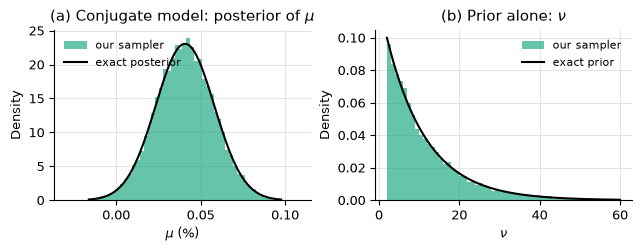

In [13]:
# Figure: our draws against the exact densities, (a) conjugate posterior of mu, (b) prior of nu
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.3, 2.4))

grid = np.linspace(exact_post.ppf(0.0005), exact_post.ppf(0.9995), 300)
ax1.hist(100 * mu_mh.ravel(), bins=60, density=True, color=COLOR_OTHER, alpha=0.6, label="our sampler")
ax1.plot(100 * grid, exact_post.pdf(grid) / 100, color="black", label="exact posterior")
ax1.set(title=r"(a) Conjugate model: posterior of $\mu$", xlabel=r"$\mu$ (%)", ylabel="Density")
ax1.legend(loc="upper left")

# (the 0.3% of draws above nu = 60 are left out of the plot)
grid = np.linspace(PRIOR["nu_min"], 60, 300)
ax2.hist(theta_mh[..., 2].ravel(), bins=58, range=(2, 60), density=True, color=COLOR_OTHER,
         alpha=0.6, label="our sampler")
ax2.plot(grid, prior_nu_minus_min.pdf(grid - PRIOR["nu_min"]), color="black", label="exact prior")
ax2.set(title=r"(b) Prior alone: $\nu$", xlabel=r"$\nu$", ylabel="Density")
ax2.legend(loc="upper right")

save_figure(fig, "known_answers.pdf")
plt.show()

**What we see.** In both panels, the histogram of our draws follows the exact density, in the centre and in the tails.

## 7. What we found

In [14]:
# Numbers quoted in the report
print(f"Prior predictive, 99% VaR (%):  median {prior_predictive.loc['99% VaR (%)', 'Prior median']}, "
      f"95% range [{prior_predictive.loc['99% VaR (%)', 'Prior 2.5%']}, "
      f"{prior_predictive.loc['99% VaR (%)', 'Prior 97.5%']}], data {var99_data:.2f}")
print(f"Prior predictive, daily sd (%): 95% range [{prior_predictive.loc['Daily sd (%)', 'Prior 2.5%']}, "
      f"{prior_predictive.loc['Daily sd (%)', 'Prior 97.5%']}], data {sd_data:.3f}")
print(f"Prior alone: largest quantile error {prior_check['difference (prior sd)'].abs().max():.3f} prior sd; "
      f"acceptance {accept_prior.min():.2f}-{accept_prior.max():.2f}")
print(f"Conjugate: largest error {conj_check['difference (exact sd)'].abs().max():.3f} posterior sd; "
      f"Pr(mu > 0 | y) {p_positive:.4f} vs exact {exact_post.sf(0):.4f}; "
      f"acceptance {accept_conj.min():.2f}-{accept_conj.max():.2f}")

Prior predictive, 99% VaR (%):  median 4.071, 95% range [0.19, 15.757], data 3.60
Prior predictive, daily sd (%): 95% range [0.075, 6.783], data 1.246
Prior alone: largest quantile error 0.027 prior sd; acceptance 0.28-0.29
Conjugate: largest error 0.005 posterior sd; Pr(mu > 0 | y) 0.9909 vs exact 0.9907; acceptance 0.44-0.45


- **Model:** $y_t \overset{\text{iid}}{\sim} t_\nu(\mu, \sigma)$ with weakly informative priors; the prior predictive check shows that they allow calm and crisis markets alike and contain our data near their centre.
- **Sampler:** our own random-walk Metropolis–Hastings on $(\mu, \log\sigma, \log(\nu-2))$, Jacobian included, tuned from the MAP and pilot runs, with 4 dispersed chains.
- **Correctness:** on two cases with an exact answer, the prior alone and a conjugate model on the real data, the sampler reproduces the exact quantiles, mean, sd and event probability, and passes every convergence target.

**Next:** `03_validation.ipynb` fits the full model on data simulated with known parameters: does it recover them, how should the step be tuned, and are its 95% intervals right 95% of the time?